<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/Taxi_Demand_RNN_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taxi demand forecasting with RNN and LSTM

**Business question:** Can recent taxi activity help us predict passenger volume in the next 30 minutes?

We use observed **passenger counts** as a demand proxy. These are not booking requests, the number of trips, or unmet demand. A taxi can carry several passengers.

**By the end of the lab, you will be able to:**
1. Analyze a time series using trend, seasonal-pattern, and autocorrelation plots.
2. Split chronologically, normalize using training data, and turn a series into input–target windows.
3. Train a simple RNN and an LSTM using the same experimental protocol.
4. Compare forecasts, errors, parameter counts, and training time against meaningful baselines.

| Activity |
|---|
| Data exploration and discussion |
| Preprocessing and window visualization |
| RNN and LSTM training |
| Prediction comparison and interpretation |
| Student experiment |

**How to run:** Extract the ZIP and open this notebook beside `data/`. Run cells from top to bottom. In Colab, the notebook can download the CSV if it is not present. CPU execution is supported; a GPU is optional. Saved outputs are an example run, and rerunning can produce different results on other hardware or package versions.

## 0. Setup
If imports fail, uncomment the installation line below. Colab normally includes these packages. After a fresh PyTorch installation, restart the kernel if necessary.

In [ ]:
# %pip install torch numpy pandas matplotlib ipython
import copy
import hashlib
import json
import random
import time
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown

SEED = 42
LOOKBACK = 48            # 48 half-hour values = previous 24 hours
BATCH_SIZE = 128
HIDDEN_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 6
LEARNING_RATE = 1e-3

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
torch.set_num_threads(2)  # Small models often run efficiently with few CPU threads.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT / 'Taxi_Demand_Lab' / 'data').exists():
    ROOT = ROOT / 'Taxi_Demand_Lab'
DATA_DIR = ROOT / 'data'
OUT = ROOT / 'outputs'
DATA_DIR.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.grid': True,
                     'grid.alpha': 0.18})
COLORS = {'Train': '#167d9a', 'Validation': '#e6a23c', 'Test': '#7952b3',
          'RNN': '#e67e22', 'LSTM': '#167d9a', 'Actual': '#202b3b'}

def show_save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('PyTorch:', torch.__version__, '| Device:', DEVICE)
print('Task: previous', LOOKBACK / 2, 'hours → next 30-minute passenger count')

PyTorch: 2.14.1+cpu | Device: cpu
Task: previous 24.0 hours → next 30-minute passenger count


## 1. Understand the data
The [Numenta Anomaly Benchmark (NAB)](https://github.com/numenta/NAB/blob/master/data/README.md) describes this series as NYC taxi passenger totals aggregated into 30-minute buckets, derived from NYC Taxi and Limousine Commission records. It includes unusual periods associated with holidays, the marathon, and a snowstorm. We retain these real changes rather than automatically deleting them as outliers.

The file has two columns: `timestamp` and `value`. We rename `value` to `passengers`.

In [ ]:
DATA_URL = 'https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/nyc_taxi.csv'
data_path = DATA_DIR / 'nyc_taxi.csv'
if not data_path.exists():
    urlretrieve(DATA_URL, data_path)

raw = pd.read_csv(data_path)
display(raw.head(8))
print('Raw shape:', raw.shape)
print('CSV SHA-256:', hashlib.sha256(data_path.read_bytes()).hexdigest())

,timestamp,value
0,2014-07-01 00:00:00,10844
1,2014-07-01 00:30:00,8127
2,2014-07-01 01:00:00,6210
3,2014-07-01 01:30:00,4656
4,2014-07-01 02:00:00,3820
5,2014-07-01 02:30:00,2873
6,2014-07-01 03:00:00,2369
7,2014-07-01 03:30:00,2064


Raw shape: (10320, 2)
CSV SHA-256: d8fa6f7f0734bf5c8be12c52a94e20a82664c397d9dec4449156bd453d32856d


### 1.1 Check timestamps, missing values, and sampling frequency
Do not interpret a missing interval as zero demand. This lab checks the original series and stops for an explicit cleaning decision if gaps or invalid values are present. That avoids silently using interpolation from future observations.

In [ ]:
df = raw.rename(columns={'value': 'passengers'}).copy()
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['passengers'] = pd.to_numeric(df['passengers'], errors='coerce')
assert df['timestamp'].notna().all(), 'Invalid timestamp: inspect before proceeding.'
assert not df['timestamp'].duplicated().any(), 'Duplicate timestamp: inspect before proceeding.'
df = df.set_index('timestamp').sort_index()
expected_index = pd.date_range(df.index.min(), df.index.max(), freq='30min')
audit = pd.Series({
    'observations': len(df),
    'first_timestamp': str(df.index.min()),
    'last_timestamp': str(df.index.max()),
    'missing_passenger_values': int(df['passengers'].isna().sum()),
    'missing_30_minute_slots': len(expected_index.difference(df.index)),
    'negative_values': int((df['passengers'] < 0).sum()),
    'zero_values': int((df['passengers'] == 0).sum()),
})
display(audit.to_frame('Data audit'))
assert df.index.equals(expected_index), 'Missing/irregular intervals: inspect before proceeding.'
assert np.isfinite(df['passengers']).all() and (df['passengers'] >= 0).all()
display(df.describe().round(2))

,Data audit
observations,10320
first_timestamp,2014-07-01 00:00:00
last_timestamp,2015-01-31 23:30:00
missing_passenger_values,0
missing_30_minute_slots,0
negative_values,0
zero_values,0


,passengers
count,10320.00
mean,15137.57
std,6939.50
min,8.00
25%,10262.00
50%,16778.00
75%,19838.75
max,39197.00


### 1.2 First define the train, validation, and test periods
Use the earliest 70% of timestamps for training, the next 15% for validation, and the final 15% for testing. **Do not randomly split overlapping time windows.**

The full-series plot below shows the experimental timeline. Seasonal summaries and autocorrelation are computed only on training data; the test set will not guide architecture selection or preprocessing.

,Split,Rows,From,Through
0,Train,7223,2014-07-01 00:00:00,2014-11-28 11:00:00
1,Validation,1549,2014-11-28 11:30:00,2014-12-30 17:30:00
2,Test,1548,2014-12-30 18:00:00,2015-01-31 23:30:00


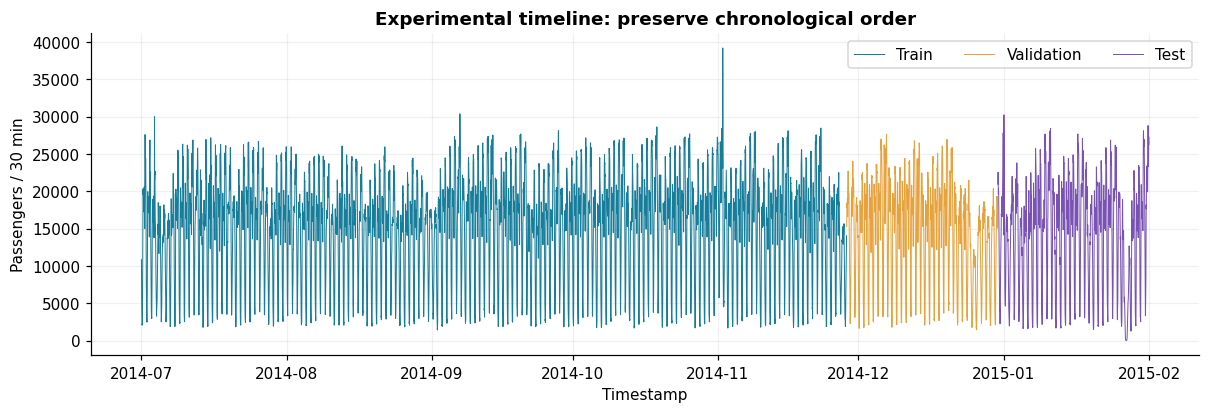

In [ ]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train_df, val_df, test_df = df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]
split_summary = pd.DataFrame([
    {'Split': name, 'Rows': len(part), 'From': part.index.min(), 'Through': part.index.max()}
    for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]
])
display(split_summary)
fig, ax = plt.subplots(figsize=(13, 3.8))
for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    ax.plot(part.index, part['passengers'], color=COLORS[name], lw=0.65, label=name)
ax.set(title='Experimental timeline: preserve chronological order', ylabel='Passengers / 30 min', xlabel='Timestamp')
ax.legend(ncol=3, loc='upper right')
show_save(fig, '01_full_series_splits')

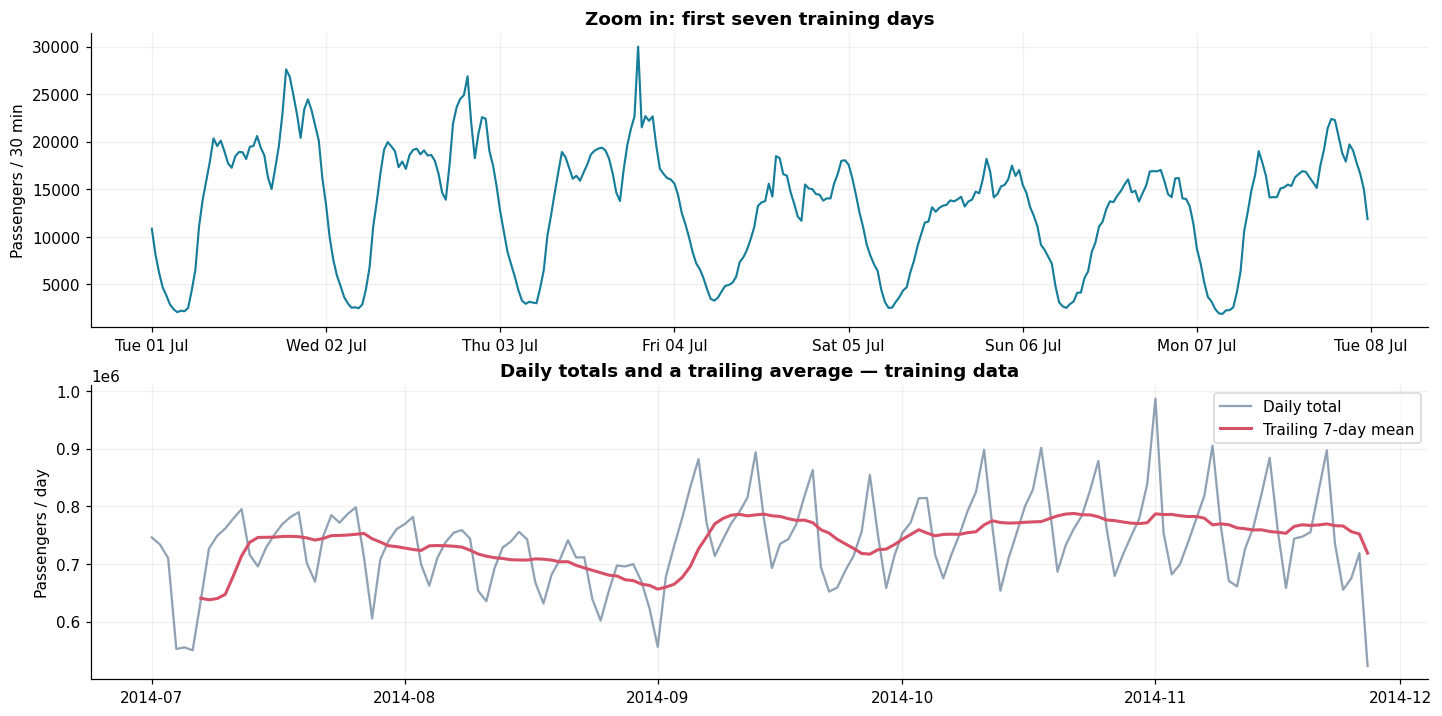

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6.4), constrained_layout=True)
week = train_df.iloc[:48 * 7]
axes[0].plot(week.index, week['passengers'], color=COLORS['Train'], lw=1.4)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b'))
axes[0].set(title='Zoom in: first seven training days', ylabel='Passengers / 30 min')
daily = train_df['passengers'].resample('D').sum(min_count=1)
daily_sizes = train_df['passengers'].resample('D').count()
daily = daily[daily_sizes == 48]  # Exclude the partial final training day.
axes[1].plot(daily.index, daily, color='#55718d', alpha=0.65, label='Daily total')
axes[1].plot(daily.index, daily.rolling(7).mean(), color='#d65067', lw=2, label='Trailing 7-day mean')
axes[1].set(title='Daily totals and a trailing average — training data', ylabel='Passengers / day')
axes[1].legend()
show_save(fig, '02_week_and_daily_trend')

### 1.3 Look for daily and weekly patterns
An RNN is useful when the order of observations carries information. Repeated activity patterns motivate both recurrent models and strong seasonal baselines.

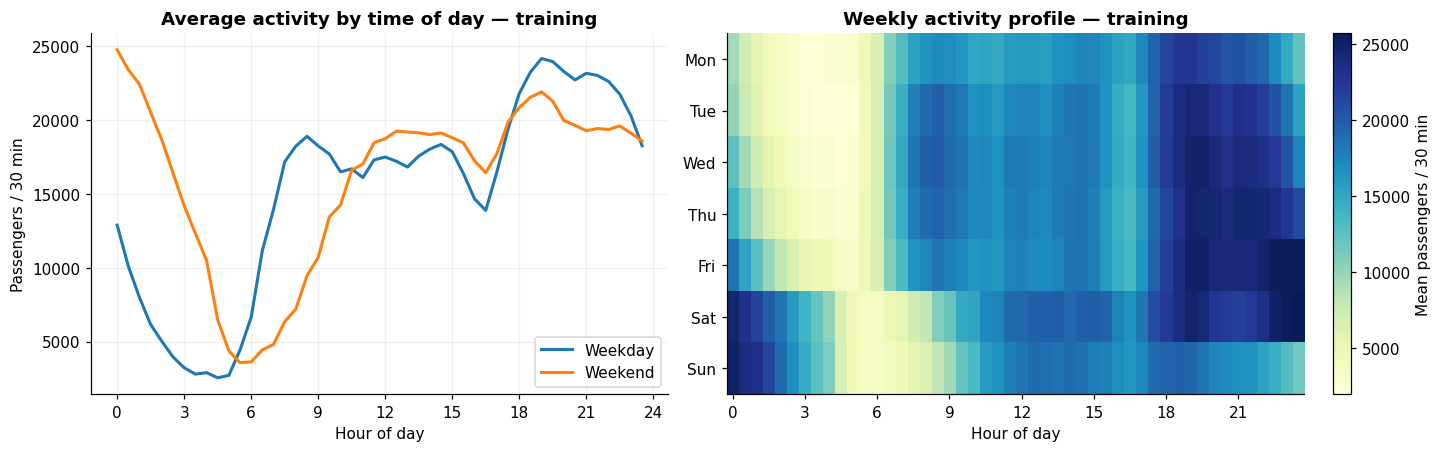

In [ ]:
eda = train_df.copy()
eda['slot'] = eda.index.hour * 2 + eda.index.minute // 30
eda['weekday'] = eda.index.dayofweek
eda['day_type'] = np.where(eda.index.dayofweek < 5, 'Weekday', 'Weekend')
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for label, part in eda.groupby('day_type'):
    profile = part.groupby('slot')['passengers'].mean()
    axes[0].plot(profile.index / 2, profile, lw=2, label=label)
axes[0].set(title='Average activity by time of day — training', xlabel='Hour of day', ylabel='Passengers / 30 min', xticks=np.arange(0, 25, 3))
axes[0].legend()
heat = eda.pivot_table(index='weekday', columns='slot', values='passengers', aggfunc='mean').reindex(range(7))
im = axes[1].imshow(heat, aspect='auto', cmap='YlGnBu')
axes[1].set(title='Weekly activity profile — training', xlabel='Hour of day', yticks=range(7), yticklabels=day_names,
            xticks=np.arange(0, 48, 6), xticklabels=np.arange(0, 24, 3))
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label='Mean passengers / 30 min')
show_save(fig, '03_daily_weekly_patterns')

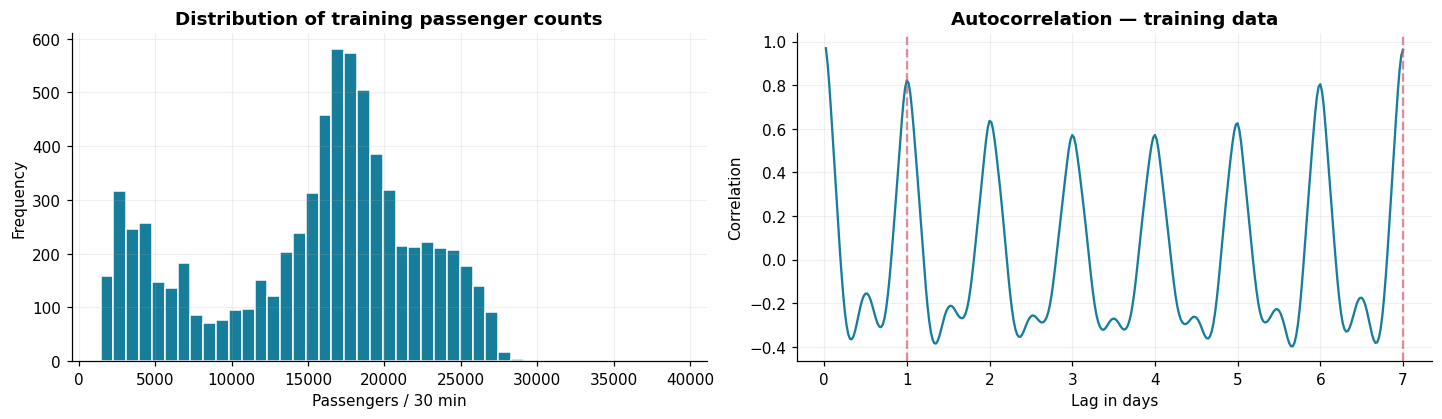

,Correlation
Lag 1 slots (0.5 hours),0.969
Lag 48 slots (24 hours),0.822
Lag 336 slots (168 hours),0.962


In [ ]:
lags = np.arange(1, 48 * 7 + 1)
acf = np.array([train_df['passengers'].autocorr(lag=int(lag)) for lag in lags])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.7), constrained_layout=True)
axes[0].hist(train_df['passengers'], bins=45, color=COLORS['Train'], edgecolor='white')
axes[0].set(title='Distribution of training passenger counts', xlabel='Passengers / 30 min', ylabel='Frequency')
axes[1].plot(lags / 48, acf, color=COLORS['Train'])
for d in [1, 7]:
    axes[1].axvline(d, color='#d65067', ls='--', alpha=0.65)
axes[1].set(title='Autocorrelation — training data', xlabel='Lag in days', ylabel='Correlation', xticks=range(8))
show_save(fig, '04_distribution_autocorrelation')
display(pd.Series({f'Lag {k} slots ({k / 2:g} hours)': train_df['passengers'].autocorr(k)
                   for k in [1, 48, 336]}).round(3).to_frame('Correlation'))

**Pause and discuss**
- Which hours are busiest? Do weekends have a different profile?
- Why might the same time yesterday be a useful forecast?
- Does strong autocorrelation prove that a model can predict every unusual event? Why not?

## 2. Preprocess and see exactly what the model receives
### 2.1 Standardize with training statistics

$$z_t = \frac{x_t - \mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}.$$

Compute the mean and standard deviation **once on the original training observations**. Apply them unchanged to validation and test data. Do not normalize each split separately: the model and targets need the same numerical meaning.

We do not smooth or remove holiday peaks; smoothing would change the prediction target. The model predicts the original half-hour passenger count after inverse scaling.

,passengers,standardized,split
timestamp,,,
2014-07-01 00:00:00,10844,-0.6573,Train
2014-07-01 00:30:00,8127,-1.0528,Train
2014-07-01 01:00:00,6210,-1.3319,Train
2014-07-01 01:30:00,4656,-1.5582,Train
2014-07-01 02:00:00,3820,-1.6799,Train
2014-07-01 02:30:00,2873,-1.8177,Train
2014-07-01 03:00:00,2369,-1.8911,Train
2014-07-01 03:30:00,2064,-1.9355,Train
2014-07-01 04:00:00,2221,-1.9126,Train


Training mean = 15,359.05; training standard deviation = 6,869.07


,mean,std
split,,
Train,0.000,1.000
Validation,-0.083,0.993
Test,-0.132,1.065


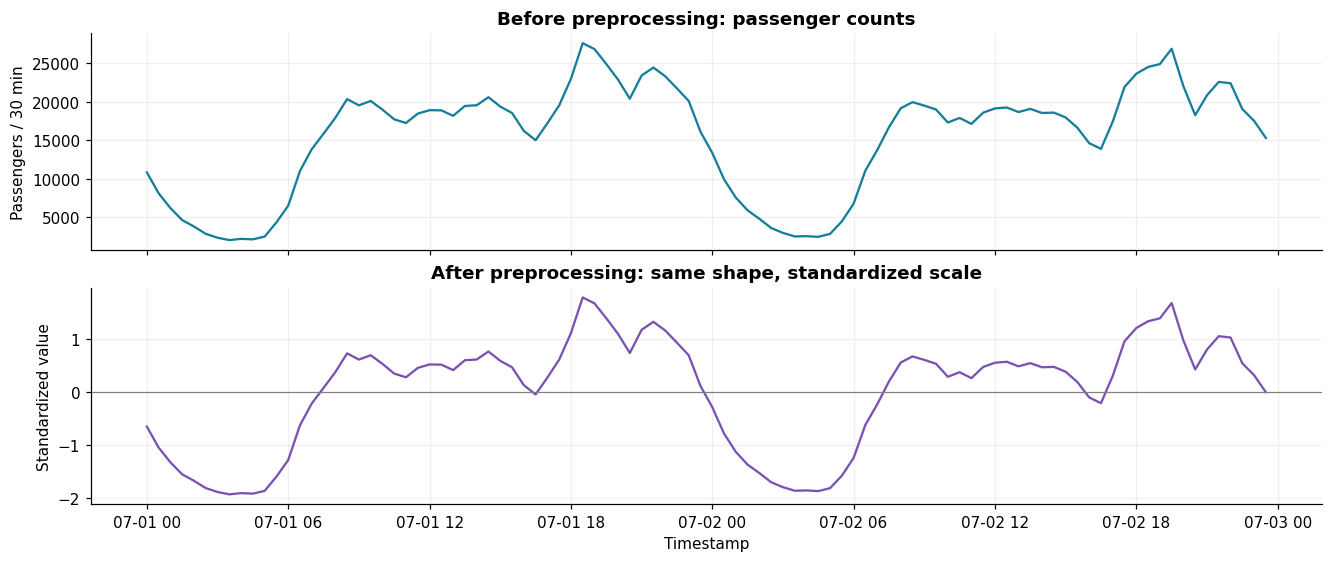

In [ ]:
train_mean = float(train_df['passengers'].mean())
train_std = float(train_df['passengers'].std(ddof=0))
assert train_std > 0
values = df['passengers'].to_numpy(dtype=np.float32)
scaled = ((values - train_mean) / train_std).astype(np.float32)
processed = df.copy()
processed['standardized'] = scaled
processed['split'] = np.where(np.arange(n) < train_end, 'Train',
                              np.where(np.arange(n) < val_end, 'Validation', 'Test'))
display(processed.head(10).round(4))
print(f'Training mean = {train_mean:,.2f}; training standard deviation = {train_std:,.2f}')
display(processed.groupby('split', sort=False)['standardized'].agg(['mean', 'std']).round(3))
processed.to_csv(OUT / 'preprocessed_series.csv')

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, constrained_layout=True)
example = processed.iloc[:96]
axes[0].plot(example.index, example['passengers'], color=COLORS['Train'])
axes[0].set(title='Before preprocessing: passenger counts', ylabel='Passengers / 30 min')
axes[1].plot(example.index, example['standardized'], color='#7952b3')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set(title='After preprocessing: same shape, standardized scale', ylabel='Standardized value', xlabel='Timestamp')
show_save(fig, '05_before_after_scaling')

### 2.2 Convert the series into supervised examples

At forecast origin $t$, all counts through $t$ are available. Predict **one** future half-hour interval:

$$X_t = [z_{t-47},\ldots,z_t], \qquad y_t = z_{t+1}.$$

| Sample | Input indices | Target index |
|---|---|---|
| 1 | 0 through 47 | 48 |
| 2 | 1 through 48 | 49 |
| 3 | 2 through 49 | 50 |

Windows move forward one interval at a time. The **target timestamp** determines the split. Validation/test windows can use observations from the preceding split because those observations would already be known at forecast time. Their inputs never include their target or future values.

This is **rolling one-step forecasting**. Later test forecasts may use newly observed earlier test counts. It is different from predicting the entire test period in advance without receiving new observations.

In [ ]:
def make_windows(series, lookback):
    X = np.stack([series[i-lookback:i] for i in range(lookback, len(series))])
    y = series[lookback:]
    target_indices = np.arange(lookback, len(series))
    return X[..., None].astype(np.float32), y[:, None].astype(np.float32), target_indices

X, y, target_indices = make_windows(scaled, LOOKBACK)
train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]
test_indices = target_indices[test_mask]
test_times = df.index[test_indices]

assert target_indices[train_mask].max() < train_end
assert target_indices[val_mask].min() == train_end
assert target_indices[test_mask].min() == val_end
assert np.allclose(X[0, :, 0], scaled[:LOOKBACK])
assert np.isclose(y[0, 0], scaled[LOOKBACK])
assert np.allclose(y_test[:, 0] * train_std + train_mean, values[test_indices], atol=0.02)

display(pd.DataFrame([
    {'Split': s, 'X shape': str(a.shape), 'y shape': str(b.shape)}
    for s, a, b in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]
]))
window_table = pd.DataFrame([
    {'Sample': j + 1, 'Input starts': df.index[j],
     'Input ends': df.index[j + LOOKBACK - 1], 'Target timestamp': df.index[j + LOOKBACK],
     'Target passengers': values[j + LOOKBACK]}
    for j in range(4)
])
display(window_table)

,Split,X shape,y shape
0,Train,"(7175, 48, 1)","(7175, 1)"
1,Validation,"(1549, 48, 1)","(1549, 1)"
2,Test,"(1548, 48, 1)","(1548, 1)"


,Sample,Input starts,Input ends,Target timestamp,Target passengers
0,1,2014-07-01 00:00:00,2014-07-01 23:30:00,2014-07-02 00:00:00,13370.0
1,2,2014-07-01 00:30:00,2014-07-02 00:00:00,2014-07-02 00:30:00,9945.0
2,3,2014-07-01 01:00:00,2014-07-02 00:30:00,2014-07-02 01:00:00,7571.0
3,4,2014-07-01 01:30:00,2014-07-02 01:00:00,2014-07-02 01:30:00,5917.0


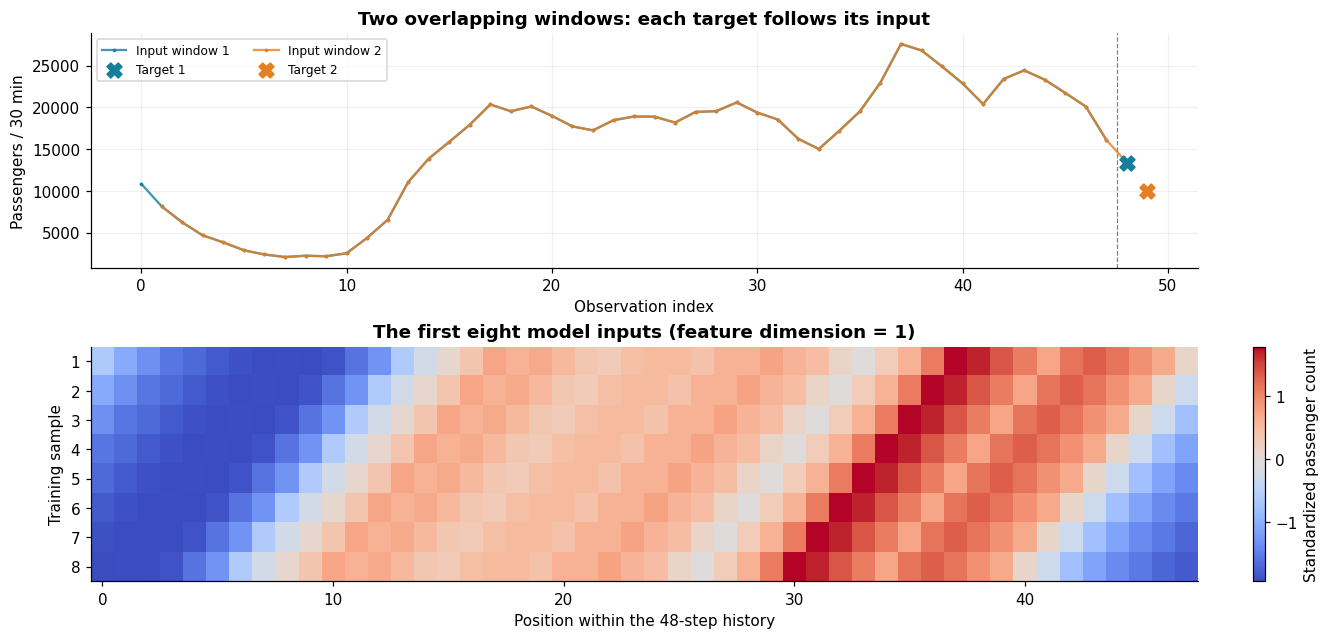

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.7), constrained_layout=True)
for j, color in [(0, '#167d9a'), (1, '#e67e22')]:
    axes[0].plot(np.arange(j, j + LOOKBACK), values[j:j+LOOKBACK], marker='.', ms=3,
                 color=color, alpha=0.8, label=f'Input window {j+1}')
    axes[0].scatter(j + LOOKBACK, values[j + LOOKBACK], s=95, marker='X', color=color,
                    label=f'Target {j+1}', zorder=5)
axes[0].axvline(LOOKBACK - 0.5, ls='--', color='gray', lw=0.8)
axes[0].set(title='Two overlapping windows: each target follows its input', xlabel='Observation index', ylabel='Passengers / 30 min')
axes[0].legend(ncol=2, fontsize=8)
image = axes[1].imshow(X_train[:8, :, 0], aspect='auto', cmap='coolwarm')
axes[1].set(title='The first eight model inputs (feature dimension = 1)', xlabel='Position within the 48-step history',
            ylabel='Training sample', yticks=np.arange(8), yticklabels=np.arange(1, 9))
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], label='Standardized passenger count')
show_save(fig, '06_sliding_windows')

### 2.3 Build mini-batches
For `batch_first=True`, the input has shape **[batch, time, features]**. Here the feature dimension is 1, not 48. Each sample is a sequence of 48 observations of the same feature.

We shuffle complete training windows, preserving the order **inside** each window. This is valid because the model resets its hidden state for every window. Validation and test loaders remain ordered.

In [ ]:
def make_loader(X, y, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                      batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=generator)

val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)
xb, yb = next(iter(make_loader(X_train, y_train, shuffle=True)))
print('One input batch:', tuple(xb.shape), '= [batch, time steps, features]')
print('One target batch:', tuple(yb.shape), '= [batch, one future value]')

One input batch: (128, 48, 1) = [batch, time steps, features]
One target batch: (128, 1) = [batch, one future value]


## 3. Train the RNN and LSTM
### 3.1 The two architectures

Both models read 48 values and send the last hidden representation to a linear regression head.

**Simple RNN:**
$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b), \qquad \hat z_{t+1} = W_o h_t + b_o.$$

**LSTM:** Uses a cell state and input, forget, and output gates to control what information is stored, retained, and exposed. It can help learn dependencies across longer sequences, but it does not guarantee better accuracy on every dataset.

We use one recurrent layer and 32 hidden units in both models. The LSTM has more parameters due to its gates, so this comparison uses equal hidden width, not equal parameter count. We report that difference.

**No hidden state is carried between windows.** PyTorch initializes it to zero for each forward call when no state is supplied. We use a unidirectional model and a linear output, not a classification softmax.

In [ ]:
class TaxiForecaster(nn.Module):
    def __init__(self, kind='RNN', hidden_size=HIDDEN_SIZE):
        super().__init__()
        recurrent_layer = {'RNN': nn.RNN, 'LSTM': nn.LSTM}[kind]
        self.recurrent = recurrent_layer(input_size=1, hidden_size=hidden_size,
                                          num_layers=1, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        all_hidden, _ = self.recurrent(x)
        last_hidden = all_hidden[:, -1, :]  # [batch, hidden_size]
        return self.head(last_hidden)       # [batch, 1]

model_specs = []
for kind in ['RNN', 'LSTM']:
    seed_everything()
    demo_model = TaxiForecaster(kind)
    model_specs.append({'Model': kind, 'Hidden units': HIDDEN_SIZE,
                        'Parameters': sum(p.numel() for p in demo_model.parameters()),
                        'Output shape': str(tuple(demo_model(xb).shape))})
display(pd.DataFrame(model_specs))

,Model,Hidden units,Parameters,Output shape
0,RNN,32,1153,"(128, 1)"
1,LSTM,32,4513,"(128, 1)"


### 3.2 Training protocol
- Both models use Adam, learning rate 0.001, MSE loss, and the same mini-batch size and data order.
- Gradient clipping at norm 1 limits unusually large updates.
- Train up to 30 epochs and stop after six epochs without validation improvement.
- Restore the checkpoint with the lowest validation MSE. **Never select a checkpoint using test error.**
- Training MSE is measured while weights are being updated; validation MSE is evaluated after the epoch. They can differ for that reason as well as because the periods have different distributions.

In [ ]:
def evaluate_mse(model, loader):
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            total += nn.functional.mse_loss(model(batch_x), batch_y, reduction='sum').item()
            count += batch_y.numel()
    return total / count

def synchronize():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def train_model(kind):
    seed_everything()
    model = TaxiForecaster(kind).to(DEVICE)
    train_loader = make_loader(X_train, y_train, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    best_loss, best_state, best_epoch, stale = float('inf'), None, 0, 0
    history = []
    synchronize()
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, count = 0.0, 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(batch_x)
            loss = criterion(prediction, batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            loss_sum += loss.item() * len(batch_x)
            count += len(batch_x)
        val_loss = evaluate_mse(model, val_loader)
        history.append({'epoch': epoch, 'train_mse': loss_sum / count, 'val_mse': val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch, stale = epoch, 0
        else:
            stale += 1
        if epoch == 1 or epoch % 5 == 0:
            print(f'{kind:4s} | epoch {epoch:02d} | train MSE {loss_sum/count:.4f} | validation MSE {val_loss:.4f}', flush=True)
        if stale >= PATIENCE:
            print(f'{kind}: early stopping at epoch {epoch}.', flush=True)
            break
    model.load_state_dict(best_state)
    synchronize()
    elapsed = time.perf_counter() - start
    history = pd.DataFrame(history)
    history.to_csv(OUT / f'{kind.lower()}_history.csv', index=False)
    torch.save({'model_state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
                'kind': kind, 'hidden_size': HIDDEN_SIZE, 'lookback': LOOKBACK,
                'train_mean': train_mean, 'train_std': train_std,
                'best_epoch': best_epoch}, OUT / f'{kind.lower()}_checkpoint.pt')
    print(f'{kind}: restored epoch {best_epoch}; training took {elapsed:.1f} seconds.', flush=True)
    return model, history, {'best_epoch': best_epoch, 'epochs_run': len(history), 'training_seconds': elapsed}

In [ ]:
rnn, rnn_history, rnn_info = train_model('RNN')

RNN  | epoch 01 | train MSE 0.6015 | validation MSE 0.1617
RNN  | epoch 05 | train MSE 0.0521 | validation MSE 0.0451
RNN  | epoch 10 | train MSE 0.0332 | validation MSE 0.0295
RNN  | epoch 15 | train MSE 0.0266 | validation MSE 0.0249
RNN  | epoch 20 | train MSE 0.0243 | validation MSE 0.0244
RNN  | epoch 25 | train MSE 0.0234 | validation MSE 0.0224
RNN  | epoch 30 | train MSE 0.0220 | validation MSE 0.0206
RNN: restored epoch 30; training took 17.9 seconds.


In [ ]:
lstm, lstm_history, lstm_info = train_model('LSTM')

LSTM | epoch 01 | train MSE 0.7214 | validation MSE 0.3688
LSTM | epoch 05 | train MSE 0.0510 | validation MSE 0.0471
LSTM | epoch 10 | train MSE 0.0258 | validation MSE 0.0245
LSTM | epoch 15 | train MSE 0.0204 | validation MSE 0.0220
LSTM | epoch 20 | train MSE 0.0183 | validation MSE 0.0237
LSTM | epoch 25 | train MSE 0.0168 | validation MSE 0.0179
LSTM | epoch 30 | train MSE 0.0159 | validation MSE 0.0174
LSTM: restored epoch 28; training took 23.1 seconds.


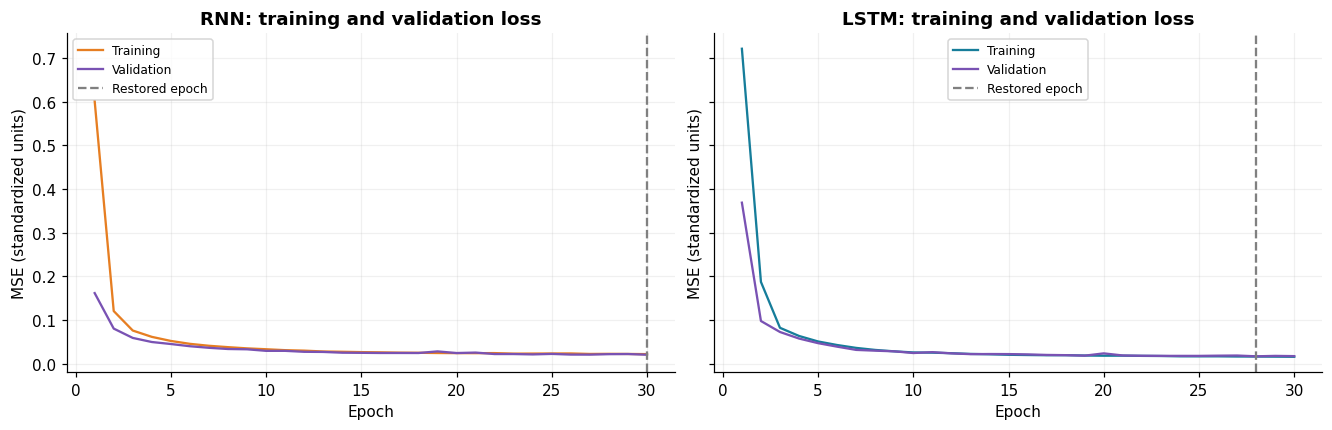

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, constrained_layout=True)
for ax, name, history, info in zip(axes, ['RNN', 'LSTM'], [rnn_history, lstm_history], [rnn_info, lstm_info]):
    ax.plot(history['epoch'], history['train_mse'], label='Training', color=COLORS[name])
    ax.plot(history['epoch'], history['val_mse'], label='Validation', color='#7952b3')
    ax.axvline(info['best_epoch'], color='gray', ls='--', label='Restored epoch')
    ax.set(title=f'{name}: training and validation loss', xlabel='Epoch', ylabel='MSE (standardized units)')
    ax.legend(fontsize=8)
show_save(fig, '07_learning_curves')

## 4. Compare predictions on the held-out test period
### 4.1 Inverse scaling and baselines

$$\hat x = \hat z\,\sigma_{\mathrm{train}} + \mu_{\mathrm{train}}.$$

We compare **all four methods on exactly the same timestamps**:

| Method | Prediction for the next interval |
|---|---|
| Persistence | Last observed passenger count |
| Same time yesterday | Passenger count 48 intervals before the target |
| RNN | Learned forecast from the 48-step window |
| LSTM | Learned forecast from the 48-step window |

Both baselines use values present in the same 48-observation history available to the models. Predictions remain continuous; we do not round or clip them before scoring.

MAE is the average absolute error in passengers per interval. RMSE penalizes larger misses more strongly. Lower is better for both. A complicated model must earn its value by improving on useful baselines.

In [ ]:
def predict_original(model, loader):
    model.eval()
    pieces = []
    with torch.no_grad():
        for batch_x, _ in loader:
            pieces.append(model(batch_x.to(DEVICE)).cpu().numpy())
    return np.concatenate(pieces).ravel() * train_std + train_mean

predictions = pd.DataFrame({
    'Actual': values[test_indices],
    'Persistence': values[test_indices - 1],
    'Same time yesterday': values[test_indices - 48],
    'RNN': predict_original(rnn, test_loader),
    'LSTM': predict_original(lstm, test_loader),
}, index=test_times)
predictions.index.name = 'timestamp'
assert predictions.notna().all().all() and np.isfinite(predictions.to_numpy()).all()
assert len(predictions) == len(X_test)
scores = []
for name in predictions.columns.drop('Actual'):
    errors = predictions[name].to_numpy() - predictions['Actual'].to_numpy()
    scores.append({'Method': name, 'MAE': np.abs(errors).mean(), 'RMSE': np.sqrt(np.mean(errors**2))})
metrics = pd.DataFrame(scores).set_index('Method')
metrics['MAE gain vs persistence (%)'] = 100 * (1 - metrics['MAE'] / metrics.loc['Persistence', 'MAE'])
metrics['Parameters'] = [0, 0, sum(p.numel() for p in rnn.parameters()), sum(p.numel() for p in lstm.parameters())]
metrics['Best epoch'] = [np.nan, np.nan, rnn_info['best_epoch'], lstm_info['best_epoch']]
metrics['Training seconds'] = [0.0, 0.0, rnn_info['training_seconds'], lstm_info['training_seconds']]
display(metrics.round(2))
predictions.to_csv(OUT / 'test_predictions.csv')
metrics.to_csv(OUT / 'test_metrics.csv')
print('Test forecasts:', len(predictions), '| Earliest:', predictions.index.min(), '| Latest:', predictions.index.max())

,MAE,RMSE,MAE gain vs persistence (%),Parameters,Best epoch,Training seconds
Method,,,,,,
Persistence,1256.319946,1661.880005,0.000000,0,NaN,0.00
Same time yesterday,3542.689941,5457.500000,-181.990005,0,NaN,0.00
RNN,807.299988,1100.619995,35.740002,1153,30.0,17.89
LSTM,767.440002,1089.420044,38.910000,4513,28.0,23.12


Test forecasts: 1548 | Earliest: 2014-12-30 18:00:00 | Latest: 2015-01-31 23:30:00


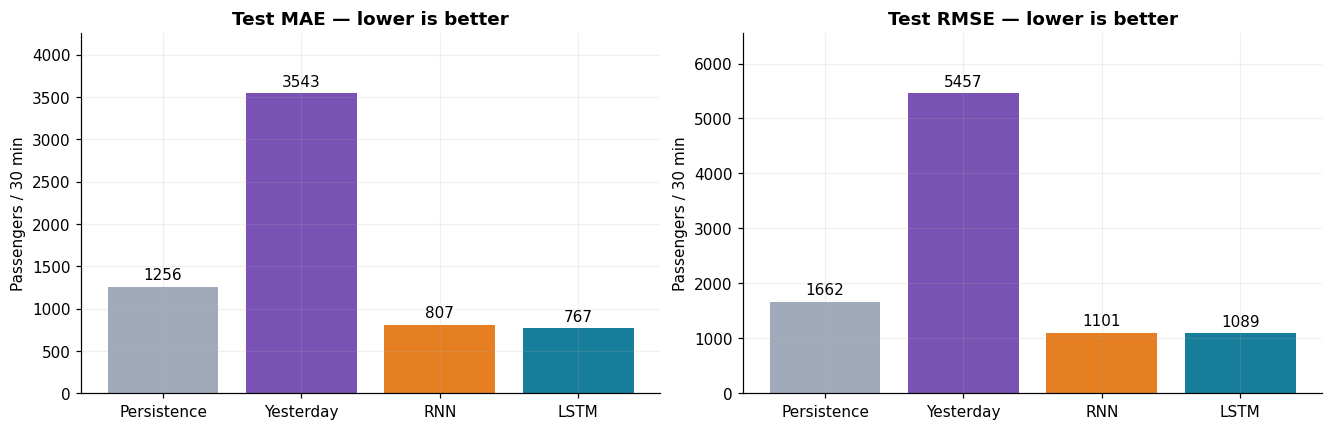

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
bar_colors = ['#a0aaba', '#7952b3', COLORS['RNN'], COLORS['LSTM']]
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    bars = ax.bar(metrics.index, metrics[metric], color=bar_colors)
    ax.bar_label(bars, fmt='%.0f', padding=3)
    ax.set(title=f'Test {metric} — lower is better', ylabel='Passengers / 30 min')
    ax.set_xticks(range(4), ['Persistence', 'Yesterday', 'RNN', 'LSTM'])
    ax.set_ylim(0, metrics[metric].max() * 1.2)
show_save(fig, '08_test_metrics')

### 4.2 Inspect the same forecast interval for both models
The first seven test days and first two test days are fixed in advance. They are not selected for favorable performance. A full test timeline follows so short examples do not hide difficult periods.

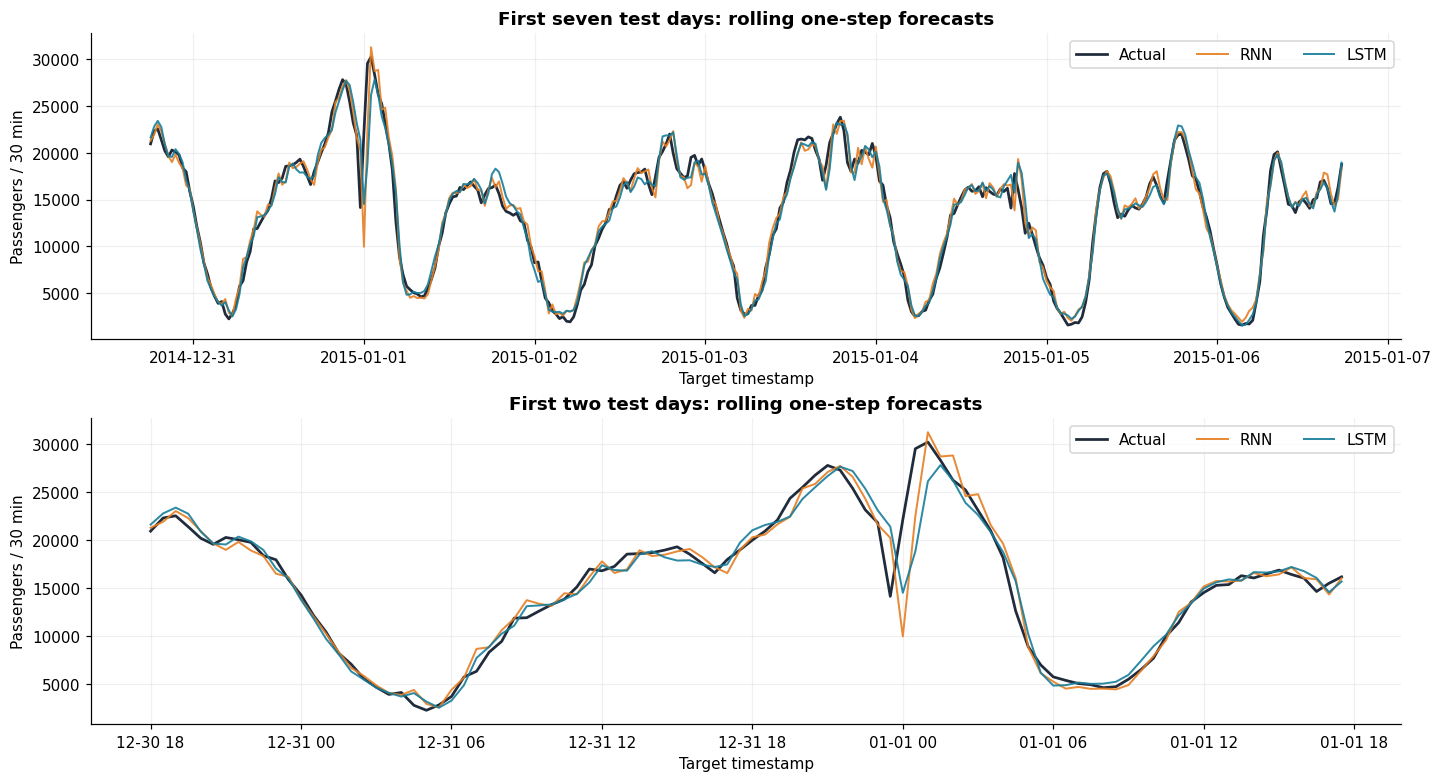

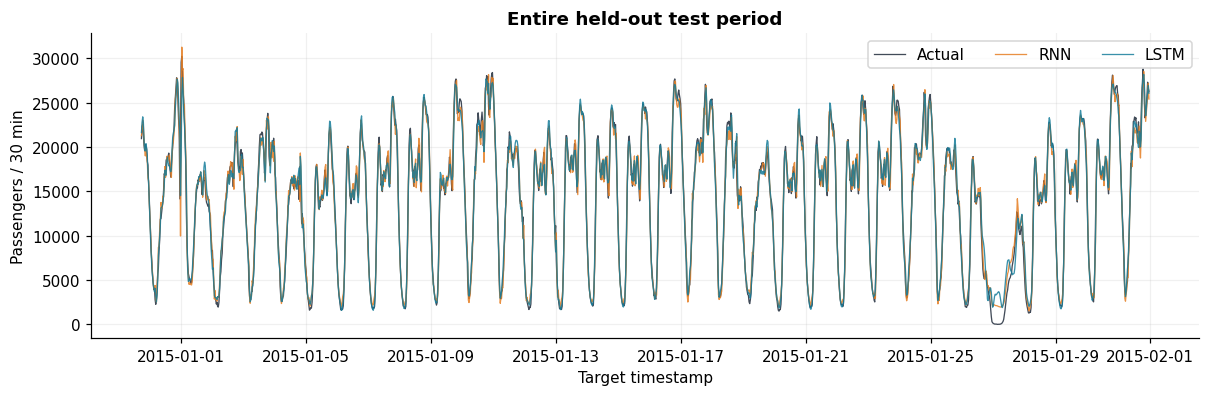

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
for ax, length, label in [(axes[0], 48 * 7, 'First seven test days'), (axes[1], 48 * 2, 'First two test days')]:
    part = predictions.iloc[:length]
    ax.plot(part.index, part['Actual'], color=COLORS['Actual'], lw=1.8, label='Actual')
    ax.plot(part.index, part['RNN'], color=COLORS['RNN'], lw=1.3, alpha=0.9, label='RNN')
    ax.plot(part.index, part['LSTM'], color=COLORS['LSTM'], lw=1.3, alpha=0.9, label='LSTM')
    ax.set(title=label + ': rolling one-step forecasts', ylabel='Passengers / 30 min', xlabel='Target timestamp')
    ax.legend(ncol=3)
show_save(fig, '09_rnn_lstm_forecasts')

fig, ax = plt.subplots(figsize=(13, 3.6))
for name in ['Actual', 'RNN', 'LSTM']:
    ax.plot(predictions.index, predictions[name], color=COLORS[name], lw=0.85, alpha=0.85, label=name)
ax.set(title='Entire held-out test period', xlabel='Target timestamp', ylabel='Passengers / 30 min')
ax.legend(ncol=3)
show_save(fig, '10_full_test_predictions')

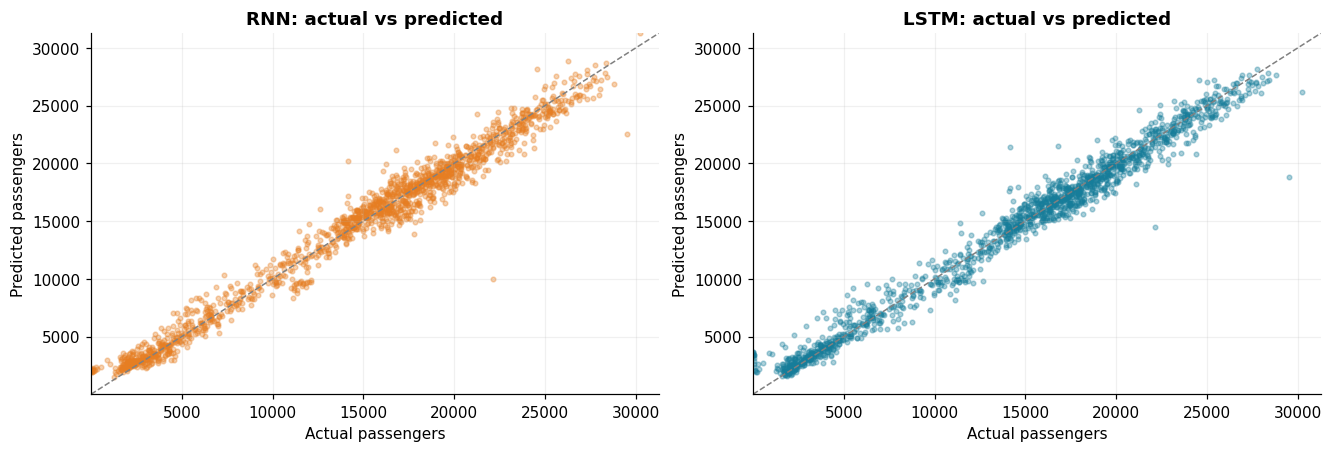

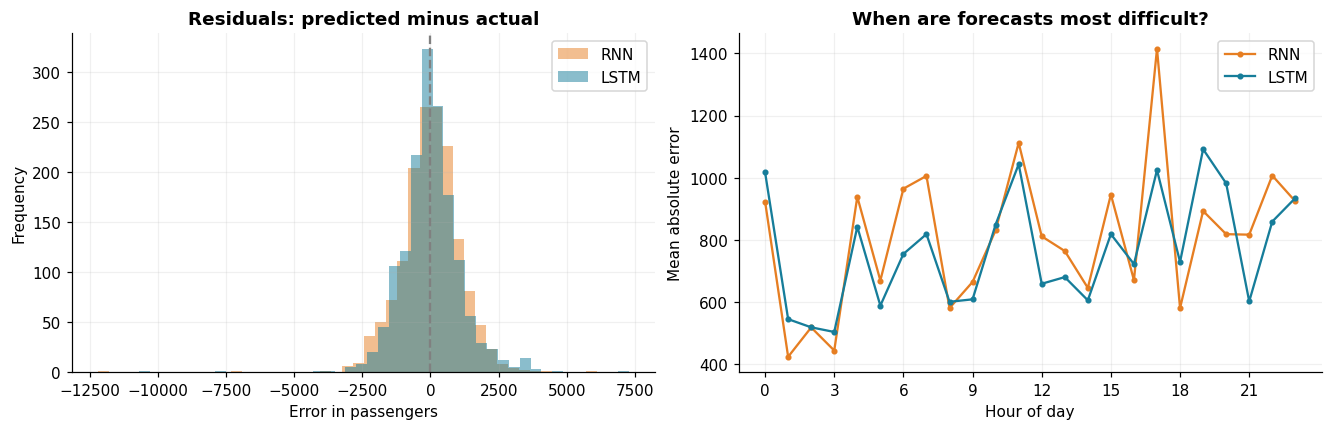

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
lo = min(predictions[['Actual', 'RNN', 'LSTM']].min())
hi = max(predictions[['Actual', 'RNN', 'LSTM']].max())
for ax, name in zip(axes, ['RNN', 'LSTM']):
    ax.scatter(predictions['Actual'], predictions[name], s=9, alpha=0.35, color=COLORS[name])
    ax.plot([lo, hi], [lo, hi], '--', color='gray', lw=1)
    ax.set(title=f'{name}: actual vs predicted', xlabel='Actual passengers', ylabel='Predicted passengers',
           xlim=(lo, hi), ylim=(lo, hi))
show_save(fig, '11_actual_vs_predicted')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for name in ['RNN', 'LSTM']:
    residual = predictions[name] - predictions['Actual']
    axes[0].hist(residual, bins=45, alpha=0.5, color=COLORS[name], label=name)
    hourly_mae = residual.abs().groupby(predictions.index.hour).mean()
    axes[1].plot(hourly_mae.index, hourly_mae, marker='o', ms=3, color=COLORS[name], label=name)
axes[0].axvline(0, color='gray', ls='--')
axes[0].set(title='Residuals: predicted minus actual', xlabel='Error in passengers', ylabel='Frequency')
axes[1].set(title='When are forecasts most difficult?', xlabel='Hour of day', ylabel='Mean absolute error', xticks=np.arange(0, 24, 3))
for ax in axes: ax.legend()
show_save(fig, '12_error_analysis')